In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import gc
import os

# 1. Mencari semua file parquet di folder raw (sesuai struktur folder)
path_raw = "../datasets/raw/2026/*.parquet"
file_paths = glob.glob(path_raw)
file_paths.sort()

print("Mulai memproses data mentah...")
list_agg = []

# 2. Looping membaca file untuk menghemat RAM
for path in file_paths:
    print(f"Membaca: {os.path.basename(path)}")
    # Hanya baca kolom yang dibutuhkan untuk agregasi awal
    df = pd.read_parquet(path, columns=['tpep_pickup_datetime', 'PULocationID'])
    
    # Pembulatan waktu ke jam (menggunakan 'h' huruf kecil untuk Pandas versi baru)
    df['pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime']).dt.floor('h')
    
    # Agregasi jumlah pickup per jam dan per zona
    df_agg_temp = df.groupby(['pickup_datetime', 'PULocationID']).size().reset_index(name='pickup_count')
    list_agg.append(df_agg_temp)
    
    # Kosongkan memori
    del df, df_agg_temp
    gc.collect()

# 3. Gabungkan hasil agregasi seluruh bulan
df_agg = pd.concat(list_agg, ignore_index=True)
# Antisipasi jika ada tumpang tindih waktu di perbatasan bulan
df_agg = df_agg.groupby(['pickup_datetime', 'PULocationID'])['pickup_count'].sum().reset_index()

# 4. Urutkan data berdasarkan Zona lalu Waktu (Wajib sebelum membuat lag)
df_agg = df_agg.sort_values(['PULocationID', 'pickup_datetime']).reset_index(drop=True)

print(f"\nData agregasi (df_agg) siap! Total baris: {len(df_agg):,}")

Mulai memproses data mentah...
Membaca: yellow_tripdata_2026-01.parquet
Membaca: yellow_tripdata_2026-02.parquet
Membaca: yellow_tripdata_2026-03.parquet
Membaca: yellow_tripdata_2026-04.parquet
Membaca: yellow_tripdata_2026-05.parquet
Membaca: yellow_tripdata_2026-06.parquet

Data agregasi (df_agg) siap! Total baris: 694,086


In [8]:
# --- A. Ekstraksi Fitur Waktu ---
df_agg['hour'] = df_agg['pickup_datetime'].dt.hour
df_agg['dayofweek'] = df_agg['pickup_datetime'].dt.dayofweek
df_agg['is_weekend'] = df_agg['dayofweek'].isin([5, 6]).astype(int)

# --- B. Ekstraksi Fitur Lag Demand (Historis Pickup) ---
# Alasan (Feature Selection): Prediksi jumlah pickup saat ini bergantung pada tren historis
df_agg['lag_1h'] = df_agg.groupby('PULocationID')['pickup_count'].shift(1)
df_agg['lag_24h'] = df_agg.groupby('PULocationID')['pickup_count'].shift(24)
df_agg['lag_1w'] = df_agg.groupby('PULocationID')['pickup_count'].shift(24 * 7)

# --- C. Feature Selection (Penghapusan Data Leakage) ---
# Alasan: Jika Anda memiliki kolom seperti tarif (fare_amount) atau cbd_congestion_fee di data asli, 
# JANGAN dimasukkan ke df_agg. Fitur tersebut baru diketahui SETELAH perjalanan selesai, 
# sehingga menyebabkan data leakage jika dipakai untuk memprediksi jumlah demand.
print("Feature engineering selesai.")

Feature engineering selesai.


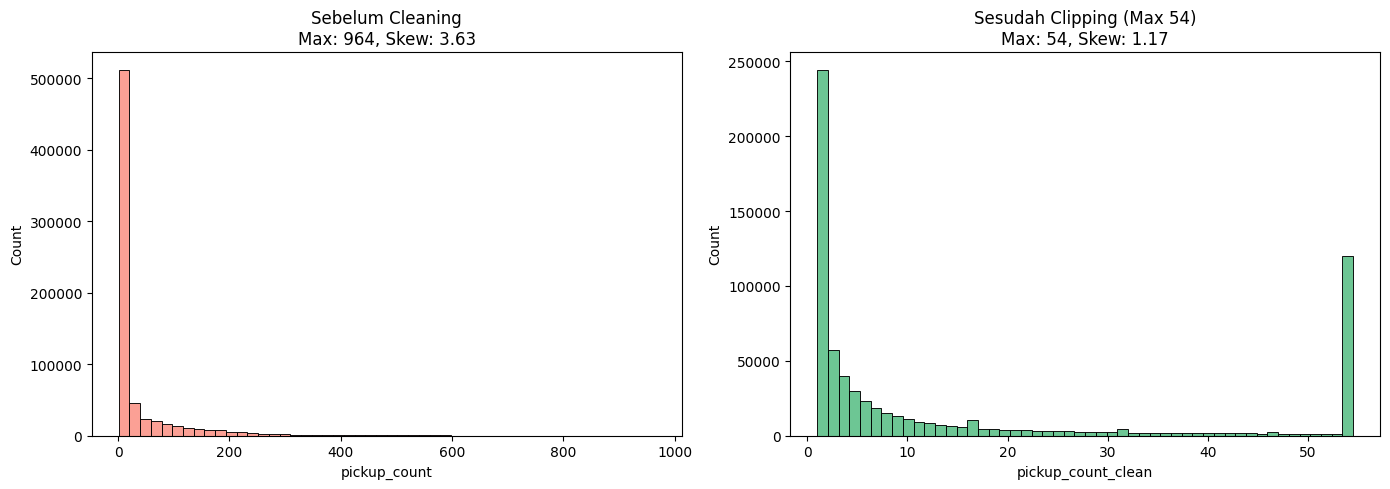

In [4]:
# --- A. Penanganan Missing Value ---
# Baris awal di bulan Januari akan memiliki NaN pada kolom lag. Imputasi dengan 0.
df_agg[['lag_1h', 'lag_24h', 'lag_1w']] = df_agg[['lag_1h', 'lag_24h', 'lag_1w']].fillna(0)

# Simpan untuk visualisasi 'Sebelum'
df_before = df_agg['pickup_count'].copy()

# --- B. Penanganan Outlier (Clipping) ---
# Alasan: Menggunakan metode IQR pada target agar model tidak overfit pada lonjakan drastis (misal event khusus)
Q1 = df_agg['pickup_count'].quantile(0.25)
Q3 = df_agg['pickup_count'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

df_agg['pickup_count_clean'] = np.clip(df_agg['pickup_count'], a_min=0, a_max=upper_bound)

# --- C. Visualisasi Perbandingan (Sebelum vs Sesudah) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_before, bins=50, ax=axes[0], color='salmon')
axes[0].set_title(f'Sebelum Cleaning\nMax: {df_before.max():.0f}, Skew: {df_before.skew():.2f}')

sns.histplot(df_agg['pickup_count_clean'], bins=50, ax=axes[1], color='mediumseagreen')
axes[1].set_title(f'Sesudah Clipping (Max {upper_bound:.0f})\nMax: {df_agg["pickup_count_clean"].max():.0f}, Skew: {df_agg["pickup_count_clean"].skew():.2f}')
plt.tight_layout()
plt.show()

# Set target final
df_agg['target_pickup'] = df_agg['pickup_count_clean']
df_agg = df_agg.drop(columns=['pickup_count', 'pickup_count_clean'])

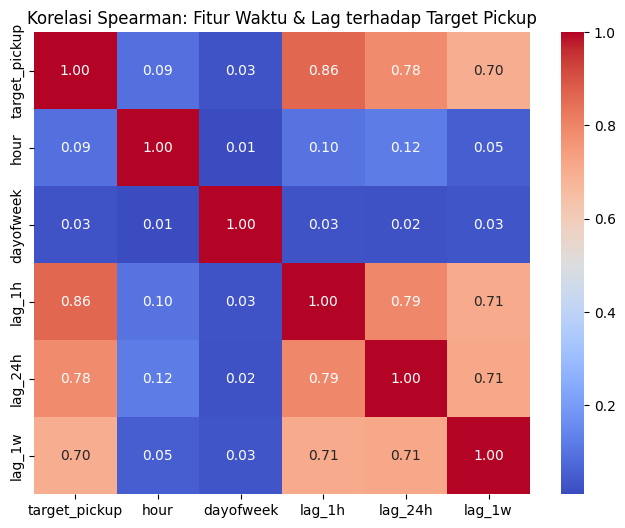

Korelasi terhadap target:
target_pickup    1.000000
lag_1h           0.860767
lag_24h          0.784753
lag_1w           0.700209
hour             0.091328
dayofweek        0.028731
Name: target_pickup, dtype: float64


In [5]:
# Pilih fitur untuk korelasi
fitur_korelasi = ['target_pickup', 'hour', 'dayofweek', 'lag_1h', 'lag_24h', 'lag_1w']
corr_matrix = df_agg[fitur_korelasi].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Korelasi Spearman: Fitur Waktu & Lag terhadap Target Pickup')
plt.show()

print("Korelasi terhadap target:")
print(corr_matrix['target_pickup'].sort_values(ascending=False))

In [9]:
# ==========================================
# CELL 2 & 3: FEATURE ENGINEERING & CLEANING
# ==========================================

# 1. Ekstraksi Fitur Waktu
df_agg['hour'] = df_agg['pickup_datetime'].dt.hour
df_agg['dayofweek'] = df_agg['pickup_datetime'].dt.dayofweek
df_agg['is_weekend'] = df_agg['dayofweek'].isin([5, 6]).astype(int)

# 2. Ekstraksi Fitur Lag Demand (Historis Pickup)
df_agg['lag_1h'] = df_agg.groupby('PULocationID')['pickup_count'].shift(1)
df_agg['lag_24h'] = df_agg.groupby('PULocationID')['pickup_count'].shift(24)
df_agg['lag_1w'] = df_agg.groupby('PULocationID')['pickup_count'].shift(24 * 7)

# 3. Penanganan Missing Value akibat Lag
df_agg[['lag_1h', 'lag_24h', 'lag_1w']] = df_agg[['lag_1h', 'lag_24h', 'lag_1w']].fillna(0)

# 4. Penanganan Outlier (Clipping) pada target
Q1 = df_agg['pickup_count'].quantile(0.25)
Q3 = df_agg['pickup_count'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

df_agg['pickup_count_clean'] = np.clip(df_agg['pickup_count'], a_min=0, a_max=upper_bound)
df_agg['target_pickup'] = df_agg['pickup_count_clean']
df_agg = df_agg.drop(columns=['pickup_count', 'pickup_count_clean'])

print("Feature Engineering dan Cleaning Selesai!")
print("Kolom yang tersedia saat ini:", df_agg.columns.tolist())

Feature Engineering dan Cleaning Selesai!
Kolom yang tersedia saat ini: ['pickup_datetime', 'PULocationID', 'hour', 'dayofweek', 'is_weekend', 'lag_1h', 'lag_24h', 'lag_1w', 'target_pickup']


In [10]:
# Eksekusi Splitting berdasarkan waktu
batas_val = pd.to_datetime('2026-05-01')
batas_test = pd.to_datetime('2026-06-01')

train_df = df_agg[df_agg['pickup_datetime'] < batas_val].copy()
val_df = df_agg[(df_agg['pickup_datetime'] >= batas_val) & (df_agg['pickup_datetime'] < batas_test)].copy()
test_df = df_agg[df_agg['pickup_datetime'] >= batas_test].copy()

print(f"Data Train (Jan-Apr) : {len(train_df):,} baris")
print(f"Data Validasi (Mei)  : {len(val_df):,} baris")
print(f"Data Uji (Juni)      : {len(test_df):,} baris")

# Memisahkan X dan y
fitur_X = ['PULocationID', 'hour', 'dayofweek', 'is_weekend', 'lag_1h', 'lag_24h', 'lag_1w']
X_train, y_train = train_df[fitur_X], train_df['target_pickup']
X_val, y_val = val_df[fitur_X], val_df['target_pickup']
X_test, y_test = test_df[fitur_X], test_df['target_pickup']

Data Train (Jan-Apr) : 475,832 baris
Data Validasi (Mei)  : 120,535 baris
Data Uji (Juni)      : 97,719 baris


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- A. Encoding & Scaling ---
fitur_kategorikal = ['PULocationID', 'hour', 'dayofweek']
fitur_numerik = ['lag_1h', 'lag_24h', 'lag_1w']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), fitur_numerik),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), fitur_kategorikal)
    ],
    remainder='passthrough' # is_weekend
)

# Fit transform
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)
print(f"Dimensi X_train setelah encoding: {X_train_processed.shape}")

# --- B. Penanganan Imbalance (Nilai Nol) ---
# Gabung sementara
train_temp = pd.DataFrame(X_train_processed)
train_temp['target'] = y_train.values

kondisi_nol = train_temp[train_temp['target'] == 0]
kondisi_aktif = train_temp[train_temp['target'] > 0]

# Logika Pengaman: Hanya lakukan undersampling JIKA data bernilai 0 ada
if len(kondisi_nol) > 0:
    # Ambil 25% dari jumlah data aktif, tapi jangan melebihi jumlah total data 0 yang tersedia
    jumlah_sampel = min(len(kondisi_nol), int(len(kondisi_aktif) * 0.25))
    undersampled_nol = kondisi_nol.sample(n=jumlah_sampel, random_state=42)
    
    # Gabung kembali dan acak
    train_balanced = pd.concat([kondisi_aktif, undersampled_nol]).sample(frac=1, random_state=42)
    print(f"Undersampling berhasil. {jumlah_sampel} baris data bernilai 0 dipertahankan.")
else:
    # Jika baris kosong ter-skip oleh groupby, langsung pakai data yang ada
    train_balanced = train_temp.sample(frac=1, random_state=42)
    print("Catatan: Tidak ada nilai target=0 di dalam dataset karena baris kosong tereliminasi saat groupby.")

# Pisahkan kembali X dan y untuk model
X_train_bal = train_balanced.drop(columns=['target']).values
y_train_bal = train_balanced['target'].values

print(f"\nRasio target=0 pada data latih final : {(y_train_bal == 0).mean():.2%}")
print("Data latih siap dimasukkan ke dalam model Machine Learning!")

Dimensi X_train setelah encoding: (475832, 297)
Catatan: Tidak ada nilai target=0 di dalam dataset karena baris kosong tereliminasi saat groupby.

Rasio target=0 pada data latih final : 0.00%
Data latih siap dimasukkan ke dalam model Machine Learning!
